# Haykin — LMS equalization and eigenvalue spread

## 1. Setup

In [1]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Parameters

In [2]:
from adsp.experiments import haykin

n_samples, n_trials, seed = 500, 200, 123
widths, n_taps, noise_var = (2.9, 3.1, 3.3, 3.5), 11, 0.001
results, spreads = {}, []

## 3. Shared generator and model factory for each channel

In [3]:
for width in widths:
  h = haykin.channel(width)
  covariance = haykin.channel_covariance(h, n_taps=n_taps, noise_var=noise_var)
  spread = stats.eigenvalue_spread(covariance)
  spreads.append(spread)
  make_data = partial(data.equalization, n_samples, h=h, decision_delay=6, noise_var=noise_var, symbol_kind="bpsk",
                      prefix=50)
  label = f"W={width}, χ={spread:.2f}"
  models = {label: partial(af.LMS, filter_order=n_taps - 1, mu=0.03 / 2)}
  results.update(training.compare(models, make_data, n_trials=n_trials, seed=seed))

## 4. Learning curves and measured tail MSE

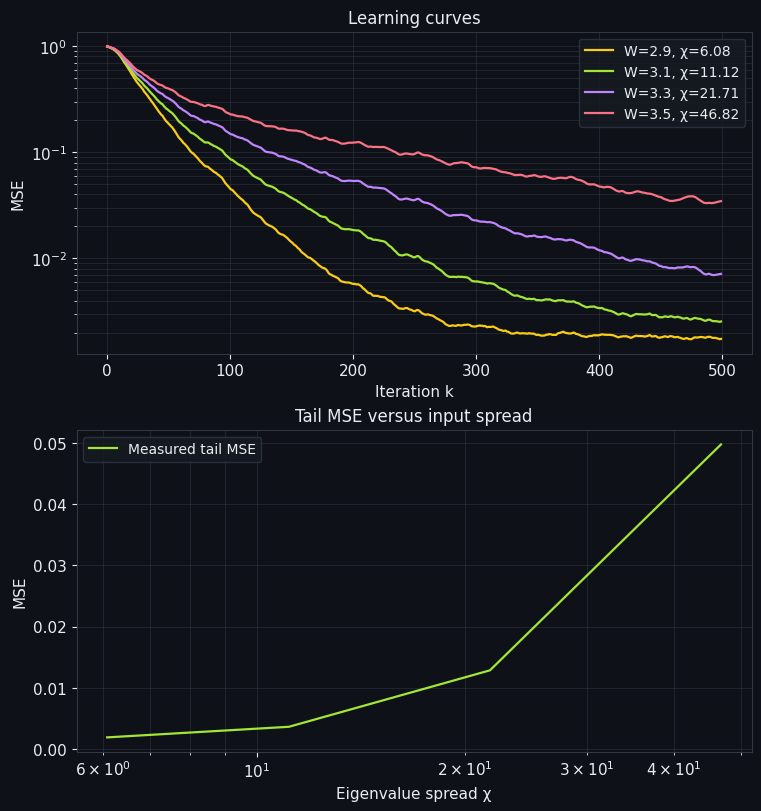

Model                                  Tail MSE     Tail MSD  Update rate
W=2.9, χ=6.08                          0.001915            —            —
W=3.1, χ=11.12                        0.0036444            —            —
W=3.3, χ=21.71                         0.012864            —            —
W=3.5, χ=46.82                         0.049739            —            —


In [4]:
fig, grid = plot.axes(rows=2)
plot.learning(results, ax=grid[0, 0], scale="log", window=15)
tail_mse = [stats.tail_mean(result.mse, tail=200) for result in results.values()]
plot.lines({"Measured tail MSE": (np.asarray(spreads), np.asarray(tail_mse))}, ax=grid[1, 0],
           xlabel="Eigenvalue spread χ", ylabel="MSE", title="Tail MSE versus input spread")
grid[1, 0].set_xscale("log")
plot.show(fig)
training.summary(results)

## 原始題目附圖

以下保留上傳 notebook 的說明圖。

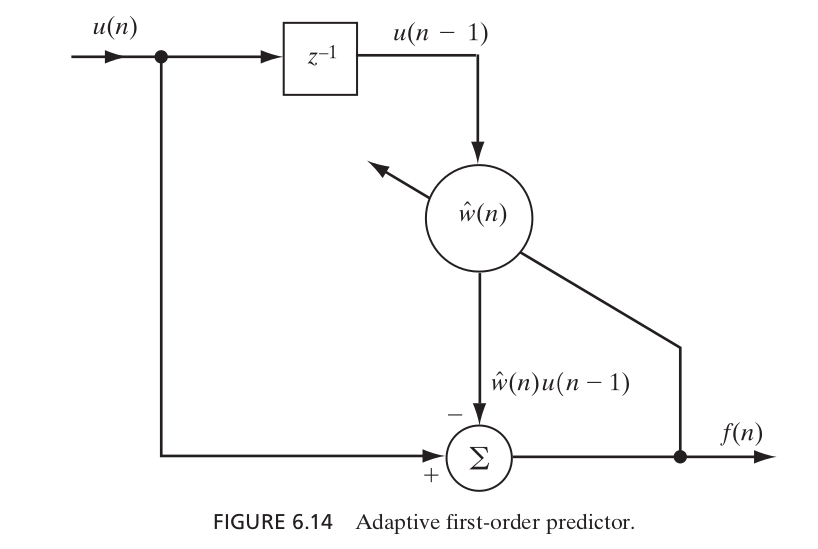

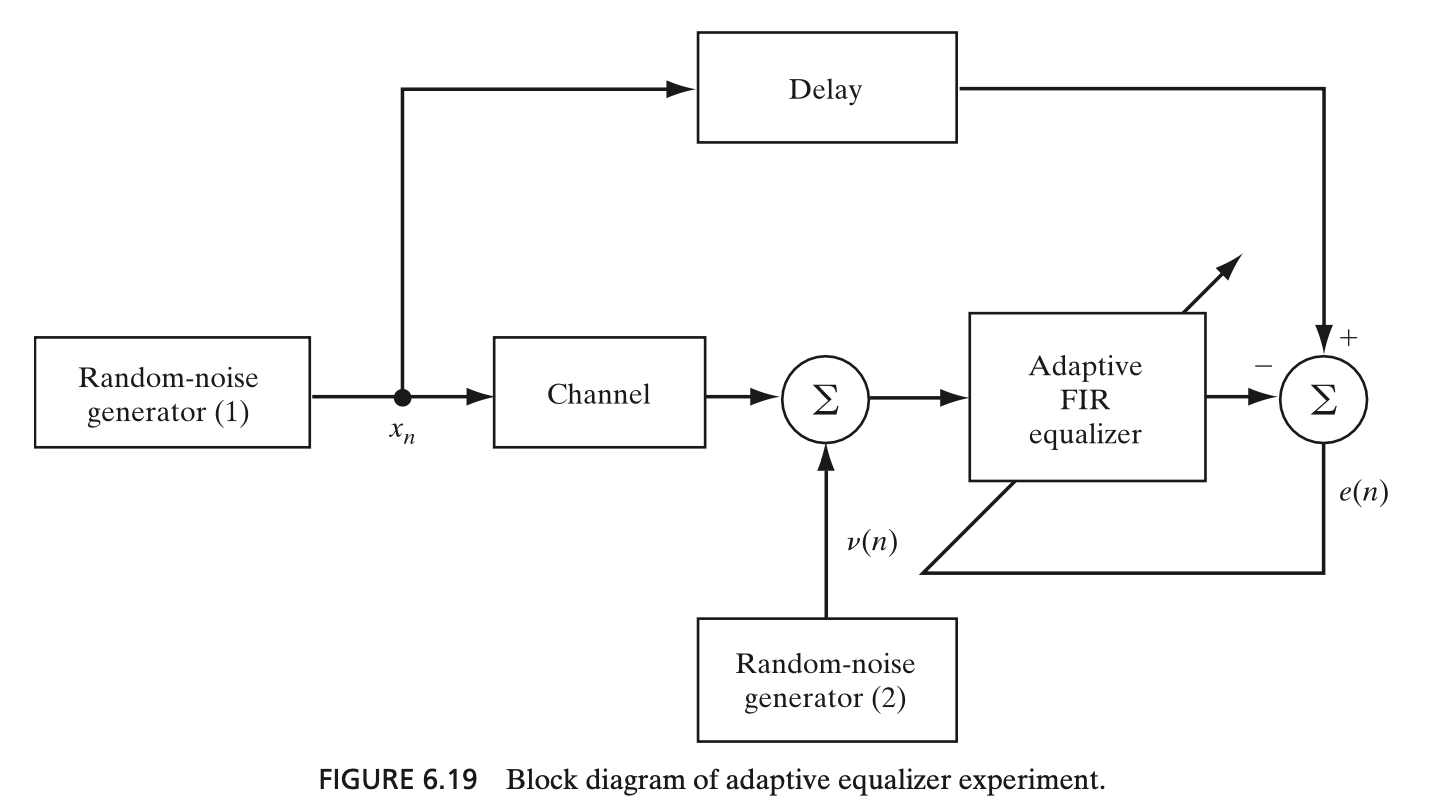